# Companion Paper II Figures & LaTeX Macros

Writes Companion Paper II's publication figures and `paper/numbers_paper2.tex` (`paper/companion_paper_imposters_criteria.tex`) when `SAVE_FIGURES = True`:
- `paper/figures/fig6_criteria_sensitivity.{pdf,png}`
- `paper/figures/fig7_wls_slope_systematic.{pdf,png}`
- `paper/figures/fig8_imposter_frontier.{pdf,png}`
- `paper/numbers_paper2.tex`


In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = True     # write PDF+PNG of each figure to paper/figures/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, style="paper", labels="paper", save_figures=SAVE_FIGURES, fig_dir="paper/figures")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"


knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
knsearch_results_latest.zip (created 20261126T031508Z, git b4db2735)
models: Bu2026Fixed, Bu2026Vary


**Fig. 6**: One-at-a-time selection-criteria sensitivity (`companion/05_criteria_and_imposters.ipynb`).


saved paper/figures/fig6_criteria_sensitivity.pdf
saved paper/figures/fig6_criteria_sensitivity.png


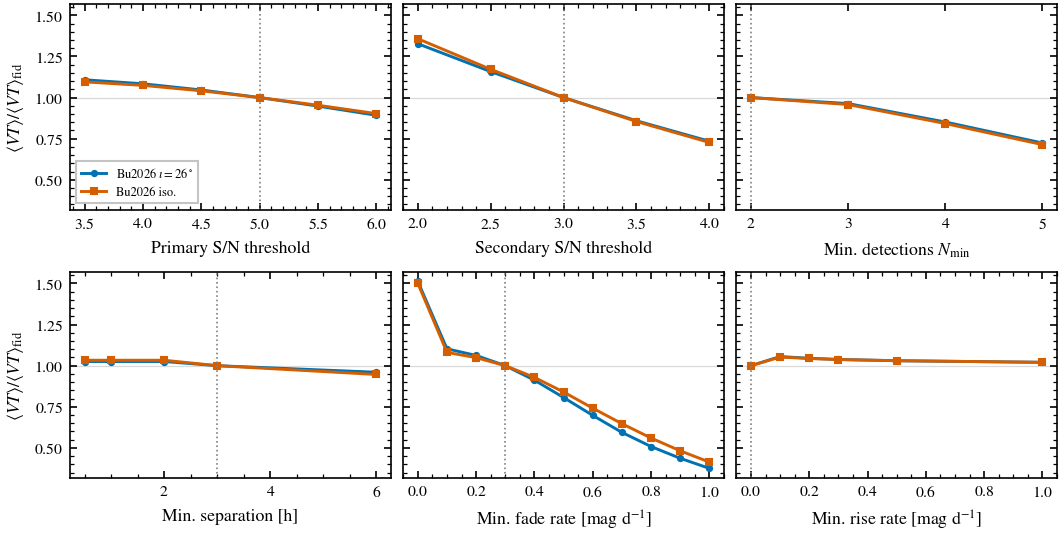

In [2]:
fig = F.criteria_one_at_a_time(ctx.snap["suite02_slices_1d"], ctx.snap["suite02_fiducial"])
ctx.save(fig, "fig6_criteria_sensitivity"); plt.show()


**Fig. 7**: Noisy-vs.-noiseless WLS slope validation & `min_rise_rate = 0` parity (`Suite 09A`).


saved paper/figures/fig7_wls_slope_systematic.pdf
saved paper/figures/fig7_wls_slope_systematic.png


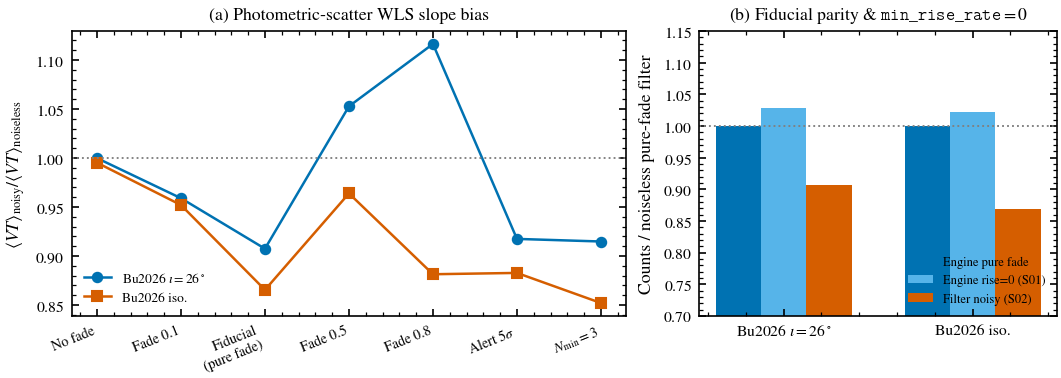

In [3]:
s09_dir = ROOT / "results" / "09_imposter_contamination"
df_9a = pd.read_csv(s09_dir / "wls_slope_and_rise_systematic.csv")
fig = F.wls_slope_systematic(df_9a)
ctx.save(fig, "fig7_wls_slope_systematic"); plt.show()


**Fig. 8**: Exploratory 8-class extragalactic contaminant yields, $d(g-r)/dt$ reddening rates, and 2D Completeness–Purity Pareto frontier (`Suite 09B`, generic ZTF exposure store).


saved paper/figures/fig8_imposter_frontier.pdf
saved paper/figures/fig8_imposter_frontier.png


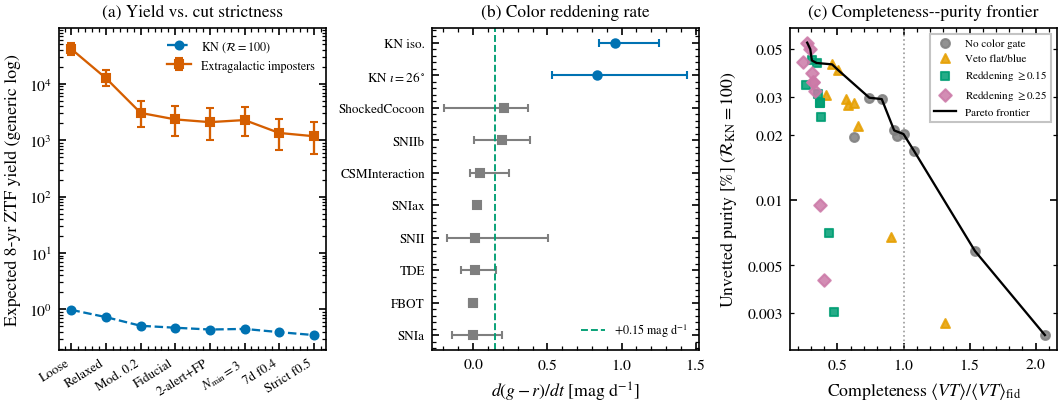

saved paper/numbers_paper2.tex


In [4]:
from knrates import macros as M
frontier_df = pd.read_csv(s09_dir / "suite09_contamination_frontier.csv")
color_df = pd.read_csv(s09_dir / "suite09_color_summary.csv")
fig = F.imposter_frontier_and_colors(frontier_df, color_df)
ctx.save(fig, "fig8_imposter_frontier"); plt.show()
if SAVE_FIGURES:
    p_tex = M.write_paper2_macros(ctx=ctx, suite09_dir=s09_dir)
    print("saved", p_tex.relative_to(ROOT))
